# The Value of Power Flexibility: Battery Day-Ahead Arbitrage, France vs Germany (2019-2025)

## Why does a battery earn less in France than in Germany, and how has the gap evolved since 2019?

### 1. How European power markets work

In Europe, electricity can be exchanged and traded between the different participating countries, whose markets are coupled through interconnectors. This helps find a balance between supply and demand. For example, if a country is producing too much electricity for its domestic demand, the excess flows to neighbouring countries where it is more expensive, within the limits of cross-border capacity. Electricity can be traded on different markets. First, the futures market is mainly used to protect energy suppliers and big industrial consumers against volatility or price peaks, but traders also use it to take positions.

The spot (day-ahead) market sets the energy price for the day after, hour by hour. This is made to adjust almost perfectly the balance between the planned production of electricity and the estimated demand for the next day. This is the most interesting market for this project, since the battery charges and discharges based on these prices.

Finally, the last market is the intraday market. Here, last-minute unexpected events are corrected up to a few minutes before delivery, to ensure that a change in the weather or the breakdown of a plant won't have a major impact on the system. This market is not modelled in this project.

### 1.1. The merit order

The day-ahead price of electricity is determined by the merit order: plants are dispatched from the lowest to the highest marginal cost (variable cost) until demand is met, and the price is set by the last plant needed, the marginal plant. All producers then receive this price. By definition, the marginal cost of solar electricity is very low, as solar panels have almost no operating costs. The merit order typically ranks generation technologies as follows, although the exact order varies with fuel and carbon prices:

1. Solar - near-zero marginal cost (no fuel)
2. Wind (onshore and offshore) – near-zero marginal cost
3. Run-of-river hydro – near-zero marginal cost, no storage
4. Nuclear – low marginal cost, high fixed costs
5. Biomass – fuel cost, often subsidised
6. Lignite – very cheap fuel but high CO2 emissions (~1.1 t/MWh)
7. Hard coal – imported fuel + CO2 (~0.9 t/MWh)
8. Gas, combined cycle (CCGT) – gas price + CO2 (~0.37 t/MWh)
9. Gas, open cycle (OCGT peakers) – low efficiency (~35-40%)
10. Oil / diesel – most expensive, rarely dispatched

Coal and gas can switch places depending on the gas-to-carbon price ratio (coal-to-gas switching). Reservoir hydro has no fixed position: it bids at its opportunity cost, often just below gas.

### 1.2. Why batteries can arbitrage

As a consequence of this ranking, a sunny day is generally synonymous with low electricity prices around midday in countries where solar energy is well developed. Yet, in the evening, when the sun sets and demand peaks, solar panels no longer produce and the price relies on more expensive technologies such as gas. This is where an arbitrage opportunity appears thanks to batteries: buy when prices are low (around midday, for example) and sell when prices get higher (during the evening peak, for example), within the same day.


### 1.3. A first look: one sunny day

In [60]:
import requests
import pandas as pd
import matplotlib.pyplot as plt

import time
from pathlib import Path

CACHE = Path("data_cache")
CACHE.mkdir(exist_ok=True)

def get_prices(bzn, start, end, max_retries=5):
    """Day-ahead prices from Energy-Charts, with disk cache and retry on 429."""
    cache_file = CACHE / f"{bzn}_{start}_{end}.csv"
    if cache_file.exists():
        s = pd.read_csv(cache_file, index_col=0, parse_dates=True).squeeze("columns")
        s.index = pd.to_datetime(s.index, utc=True).tz_convert("Europe/Paris")
        return s

    url = "https://api.energy-charts.info/price"
    wait = 10
    for attempt in range(max_retries):
        r = requests.get(url, params={"bzn": bzn, "start": start, "end": end}, timeout=30)
        if r.status_code == 429:
            print(f"429 on {bzn} {start} – waiting {wait}s (attempt {attempt+1}/{max_retries})")
            time.sleep(wait)
            wait *= 2
            continue
        r.raise_for_status()
        data = r.json()
        s = pd.Series(data["price"],
                      index=pd.to_datetime(data["unix_seconds"], unit="s", utc=True),
                      name=bzn).tz_convert("Europe/Paris")
        s.to_csv(cache_file)
        time.sleep(3)
        return s

    raise RuntimeError(f"Still rate-limited after {max_retries} attempts for {bzn} {start}")

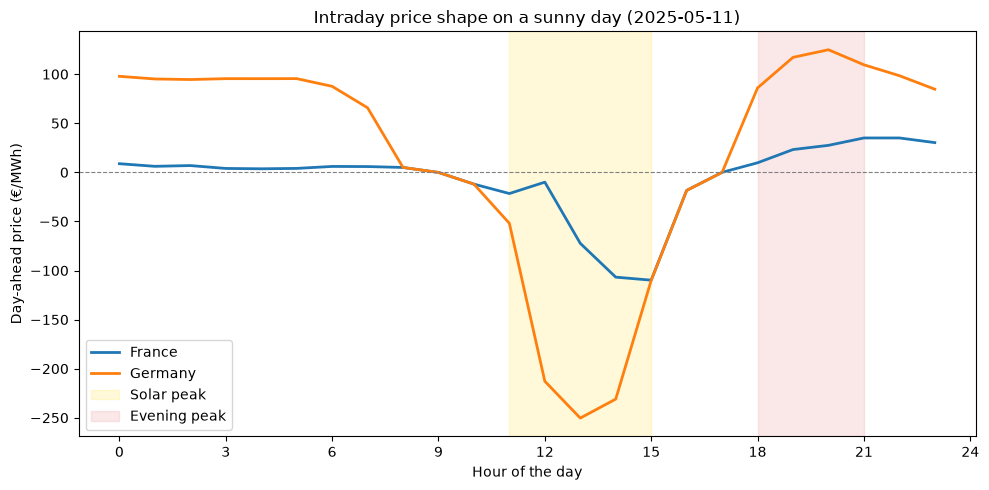

In [61]:
day = "2025-05-11"
fr = get_prices("FR", day, day)
de = get_prices("DE-LU", day, day)

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(fr.index.hour + fr.index.minute / 60, fr.values, label="France", lw=2)
ax.plot(de.index.hour + de.index.minute / 60, de.values, label="Germany", lw=2)
ax.axhline(0, color="grey", lw=0.8, ls="--")
ax.axvspan(11, 15, color="gold", alpha=0.15, label="Solar peak")
ax.axvspan(18, 21, color="tab:red", alpha=0.10, label="Evening peak")
ax.set_xlabel("Hour of the day")
ax.set_ylabel("Day-ahead price (€/MWh)")
ax.set_title(f"Intraday price shape on a sunny day ({day})")
ax.set_xticks(range(0, 25, 3))
ax.legend()
plt.tight_layout()
plt.show()

Source: Energy-Charts (Fraunhofer ISE), EPEX Spot day-ahead prices.

This first shape is very consistent with the generation mix of each country. On a sunny day, during the solar peak (11h–15h), electricity in Germany is cheaper, as solar accounts for a much larger share of the German generation mix than of the French one. But when the sun sets and solar panels can no longer produce electricity, the system has to rely on other technologies to keep meeting demand. We can see that German prices explode in the evening, while French prices stay lower than the German ones, as nuclear power continues to cover most of the French demand at a low marginal cost.

When looking at this graph with a battery buying low and selling high in mind, the answer seems obvious: we clearly want to install our battery in Germany. But this graph only represents one day, which happens to be a Sunday with low demand, and it may not be representative. To resolve this problem, I tried to be more precise with a mean over the entire month :

### 1.4. Average price profile over a month

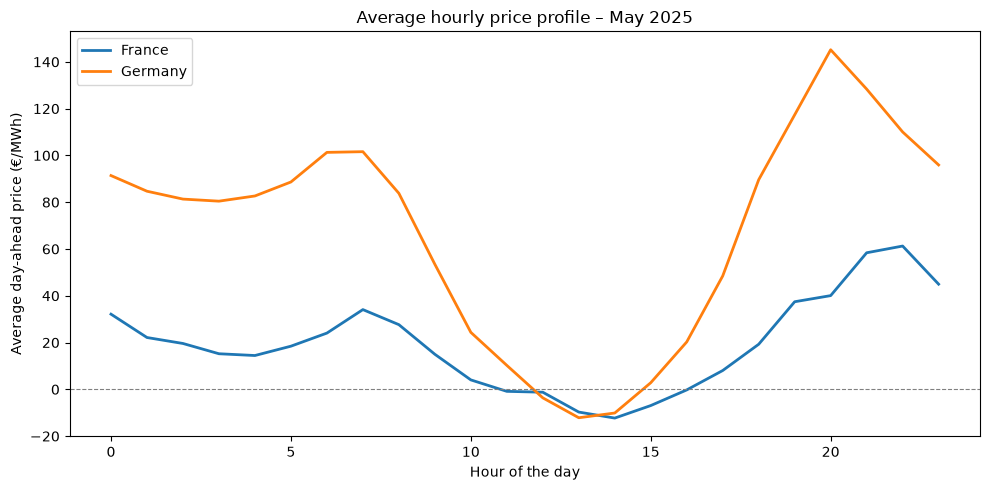

In [62]:
start, end = "2025-05-01", "2025-05-31"
fr_m = get_prices("FR", start, end)
de_m = get_prices("DE-LU", start, end)

profile = pd.DataFrame({
    "France": fr_m.groupby(fr_m.index.hour).mean(),
    "Germany": de_m.groupby(de_m.index.hour).mean(),
})

ax = profile.plot(figsize=(10, 5), lw=2)
ax.axhline(0, color="grey", lw=0.8, ls="--")
ax.set_xlabel("Hour of the day")
ax.set_ylabel("Average day-ahead price (€/MWh)")
ax.set_title("Average hourly price profile – May 2025")
plt.tight_layout()
plt.show()

Source: Energy-Charts (Fraunhofer ISE), EPEX Spot day-ahead prices.

The monthly average confirms what we observed on a single day. Even if prices during the solar peak are almost the same in both countries, around or slightly below zero, prices in the evening and at night are much higher in Germany, and a battery in Germany would likely be far more profitable. On average in May 2025, the gap between the cheapest and the most expensive hour is about 155 €/MWh in Germany, against about 75 €/MWh in France.

To compare the results across years, we average the prices hour by hour over every day of May, to get a single profile for May 2019, May 2022, May 2024 and May 2025. To keep the comparison readable, we do not plot every year but select four years that each represent a distinct market regime:

- 2019 is the baseline, before the solar boom and the energy crisis.
- 2022 is the peak of the energy crisis, with record gas prices and reduced French nuclear availability.
- 2024 and 2025 reflect the current market, with a high share of solar energy in both countries.

The other years are left out of this comparison because they mainly reflect exceptional or transitional conditions. In 2020, electricity demand dropped sharply during the COVID-19 lockdowns, which distorted prices. 2021 and 2023 are transition years, respectively into and out of the energy crisis: their prices mix several regimes and add little to the comparison. However, all years from 2019 to 2025 are included in the battery simulation, so that no period is excluded from the final results.

### 1.5. How the daily price shape has evolved since 2019

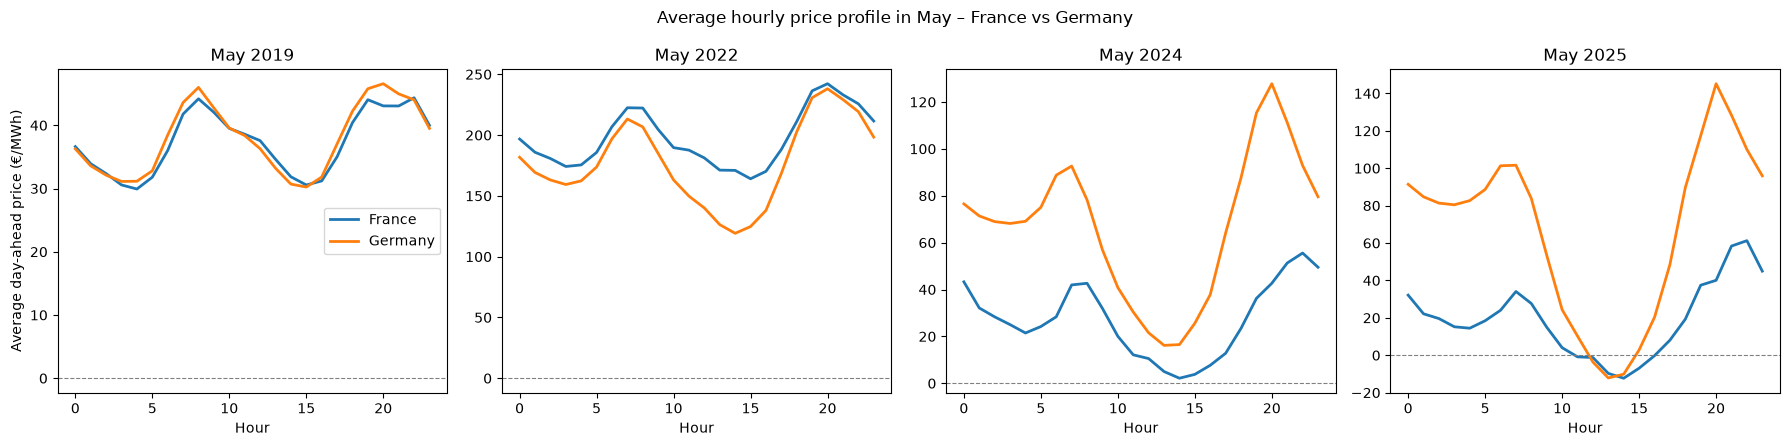

zone  France  Germany  DE/FR ratio
year                              
2019    23.4     25.0         1.07
2022    96.0    132.3         1.38
2024    64.0    116.3         1.82
2025    83.3    161.6         1.94


In [63]:
years = [2019, 2022, 2024, 2025]
fig, axes = plt.subplots(1, len(years), figsize=(18, 4.5), sharey=False)

spreads = []
for ax, y in zip(axes, years):
    start, end = f"{y}-05-01", f"{y}-05-31"
    fr_y = get_prices("FR", start, end)
    de_y = get_prices("DE-LU", start, end)

    prof = pd.DataFrame({
        "France": fr_y.groupby(fr_y.index.hour).mean(),
        "Germany": de_y.groupby(de_y.index.hour).mean(),
    })
    prof.plot(ax=ax, lw=2, legend=(y == years[0]))
    ax.axhline(0, color="grey", lw=0.8, ls="--")
    ax.set_title(f"May {y}")
    ax.set_xlabel("Hour")

    # average daily spread (max - min of each day)
    for name, s in [("France", fr_y), ("Germany", de_y)]:
        daily = s.groupby(s.index.date).agg(lambda x: x.max() - x.min())
        spreads.append({"year": y, "zone": name, "avg_daily_spread": daily.mean()})

axes[0].set_ylabel("Average day-ahead price (€/MWh)")
plt.suptitle("Average hourly price profile in May – France vs Germany")
plt.tight_layout()
plt.show()

spread_table = pd.DataFrame(spreads).pivot(index="year", columns="zone", values="avg_daily_spread").round(1)
spread_table["DE/FR ratio"] = (spread_table["Germany"] / spread_table["France"]).round(2)
print(spread_table)

Source: Energy-Charts (Fraunhofer ISE), EPEX Spot day-ahead prices.

A trend seems to be appearing. The average daily spread, which is what a battery seeks to capture, has grown in both countries, but much faster in Germany: the ratio between the German and the French spread rose from 1.07 in 2019 to 1.94 in 2025. Whereas prices in France and Germany were almost the same at every hour of the day in 2019, with a small daily spread, we can see an increasing gap between the two countries. 2022 stands out as an exception, with French prices above German ones due to reduced nuclear availability. In 2024 and 2025, the gap grows particularly outside the solar peak: German electricity prices are not exceptionally low during the solar peak, where they are close to French prices, but they are exceptionally high during the other hours of the day.

### 2. The battery simulation

To simulate our battery that we will put and install directly in the electricity markets, we have to define how the optimising function of our battery and define the physical constraints associated to the battery.

### 2.1. Model and assumptions

We simulate a 1 MW / 2 MWh battery that trades on the day-ahead market. For each day, we solve a linear optimisation problem under constraints: knowing the hourly prices $p_t$, the battery chooses when to charge and discharge in order to maximise its daily profit.

Decision variables (for each hour $t$):
- $c_t$: charging power (MW)
- $d_t$: discharging power (MW)
- $s_t$: state of charge at the end of hour $t$ (MWh)

To modelise our optimisation function, we want to maximise our profit, represented by $d_t$ $\times$ $p_t$  because every time we discharge power at time t, we sell it at the price $p_t$. With the same method, we need to substract $c_t$ $\times$ $p_t$ as when we charge power at time t, we buy it at the price $p_t$. Finally, we need to represent the degradation of our battery.

Finally, we have our final objective: maximise the daily profit represented by : 

$$\max \sum_{t} \left[ p_t \,(d_t - c_t) - k \, d_t \right]$$

where $k$ is a degradation cost per MWh discharged that we will determine later.

Constraints:
- Power limit: $0 \le c_t \le P$ and $0 \le d_t \le P$, with $P = 1$ MW because the battery can't charge or discharge fatser than its rated power (P).
- Capacity limit: $0 \le s_t \le E$, with $E = 2$ MWh the capacity
- Energy balance: $s_t = s_{t-1} + \eta \, c_t - \dfrac{d_t}{\eta}$, with $\eta = \sqrt{0.85}$ (85% round-trip efficiency / source : Cole et al. 2025 on the NLR website)
The state of charge at the end of period t is the state of charge at the beginning plus what we add (we multiply by $\eta$ to consider the efficiency) minus what we take out (we divide by $\eta$).
- The battery starts and ends each day half full: $s_{0} = s_{T} = E/2$
- Charging + discharging power: $c_t + d_t ≤ P$. Without this constraint, the optimiser could charge and discharge in the same hour during negative prices, using round-trip losses to absorb extra energy.

Assumptions:
- Perfect foresight: the battery knows all prices of the day in advance.
- Price taker: the battery is too small to move market prices.
- Only day-ahead arbitrage is modelled, without intraday trading or ancillary services.

Determination of our factor k :
k depends on the price of the battery as it depends on how much it would cost us to replace it. To try being as realistic as possible in our model, we can't take a constant k because the price of the battery between 2019 and 2025 is (very) different.

Degradation cost $k$

Each MWh discharged wears the battery a little. We price this degradation as the replacement cost of the battery spread over its cycle life:

$$k = \frac{\text{battery pack price (€/MWh of capacity)}}{\text{cycle life (number of full cycles)}}$$

Level in 2025 : BloombergNEF reports an average pack price of 70 \$/kWh for stationary storage in 2025. With a conservative cycle life of 6,000 full cycles for LFP storage cells (CATL announces up to 10,000), this gives $k \approx 70\,000 / 6\,000 \approx 12$ \$/MWh, i.e. about 10 €/MWh.

Evolution since 2019 : Battery prices have fallen sharply since 2019, so the degradation cost was higher in earlier years. We scale $k$ with BloombergNEF's annual average pack price (all segments), which is the only public series covering the whole period:

$$k_y = k_{2025} \times \frac{\text{pack price}_y}{\text{pack price}_{2025}}$$

| Year | Average pack price (\$/kWh) | $k$ (€/MWh) |
|---|---|---|
| 2019 | 156 | 14.4 |
| 2020 | 137 | 12.7 |
| 2021 | 132 | 12.2 |
| 2022 | 151 | 14.0 |
| 2023 | 139 | 12.9 |
| 2024 | 115 | 10.6 |
| 2025 | 108 | 10.0 |

*Source: BloombergNEF, annual Lithium-Ion Battery Price Survey (press releases, 2019–2025).*

### 2.2. Price data, 2019-2025

In [64]:
def get_range(bidding_zone, start_year, end_year):
    parts = []
    for y in range(start_year, end_year + 1):
        for m in range (1,13):
            start = pd.Timestamp(year=y, month=m, day=1)
            end = start + pd.offsets.MonthEnd(0)
            parts.append(get_prices(bidding_zone,start.strftime("%Y-%m-%d"), end.strftime("%Y-%m-%d")))
    s = pd.concat(parts)
    return s.resample("1h").mean()

fr_all = get_range("FR",2019,2025)
de_all = get_range("DE-LU",2019,2025)

print(f"France: {len(fr_all):,} hours | Germany: {len(de_all):,} hours")


France: 61,368 hours | Germany: 61,368 hours


In [65]:
print(f"Missing values – France: {fr_all.isna().sum()} | Germany: {de_all.isna().sum()}")

Missing values – France: 0 | Germany: 0


Our data is collected and has no missing values so we can continue with the optimisation. To optimise our function, we will use linprog with the HiGHS method.

### 2.3. Annual arbitrage revenues

In [ ]:
import numpy as np
from scipy.optimize import linprog

P, E, RTE = 1.0, 2.0, 0.85

def optimise_day(prices, k, P=P, E=E, rte=RTE, exclusive=True, return_schedule=False):
    p = np.asarray(prices, dtype=float)
    T = len(p)
    eta = np.sqrt(rte)
    cost = np.concatenate([p, -p + k, np.zeros(T)])

    A_eq, b_eq = [], []
    for t in range(T):
        row = np.zeros(3 * T)
        row[t] = -eta
        row[T + t] = 1 / eta
        row[2 * T + t] = 1
        if t > 0:
            row[2 * T + t - 1] = -1
        A_eq.append(row)
        b_eq.append(E / 2 if t == 0 else 0.0)
    end = np.zeros(3 * T); end[-1] = 1
    A_eq.append(end); b_eq.append(E / 2)

    A_ub, b_ub = None, None
    if exclusive:
        A_ub = np.zeros((T, 3 * T))
        A_ub[np.arange(T), np.arange(T)] = 1
        A_ub[np.arange(T), T + np.arange(T)] = 1
        b_ub = np.full(T, P)

    bounds = [(0, P)] * (2 * T) + [(0, E)] * T
    res = linprog(cost, A_ub=A_ub, b_ub=b_ub, A_eq=np.array(A_eq), b_eq=b_eq,
                  bounds=bounds, method="highs")
    if not res.success:
        return (np.nan, None) if return_schedule else np.nan
    if return_schedule:
        return -res.fun, res.x
    return -res.fun

def daily_revenues(s, k):
    s = s.dropna()
    out = {}
    for day, x in s.groupby(s.index.date):
        if len(x) < 23:
            continue
        k_day = k[day.year] if isinstance(k, dict) else k
        out[day] = optimise_day(x.values, k_day)
    return pd.Series(out)

# to test our results in the sunny day we used earlier
test_day = fr_all.loc["2025-05-11"]
print(f"Test in France, 11 May 2025: {optimise_day(test_day.values, 10):.0f} € for the day")
test_day_2 = de_all.loc["2025-05-11"]
print(f"Test in Germany, 11 May 2025: {optimise_day(test_day_2.values, 10):.0f} € for the day")


Test in France, 11 May 2025: 256 € for the day
Test in Germany, 11 May 2025: 726 € for the day


The battery earns 256 € in France and 726 € in Germany. In both countries, most of the gain comes from being paid to charge during the negative prices of the afternoon. The German battery also earns more by discharging at high prices in the morning and in the evening. This single day is consistent with the price shapes observed earlier, but the full simulation is needed to draw conclusions.
To continue, we will run the simulation on our 7 years (from 2019 to 2025). As we said earlier, we will adapt the k depending on the year we are.

Annual day-ahead arbitrage revenue (k€/MW/year)
      France  Germany  DE/FR ratio
2019     3.5      5.7         1.63
2020     4.7      8.2         1.74
2021    26.4     33.2         1.26
2022    69.2     92.2         1.33
2023    35.5     44.9         1.26
2024    38.4     59.2         1.54
2025    48.4     68.6         1.42


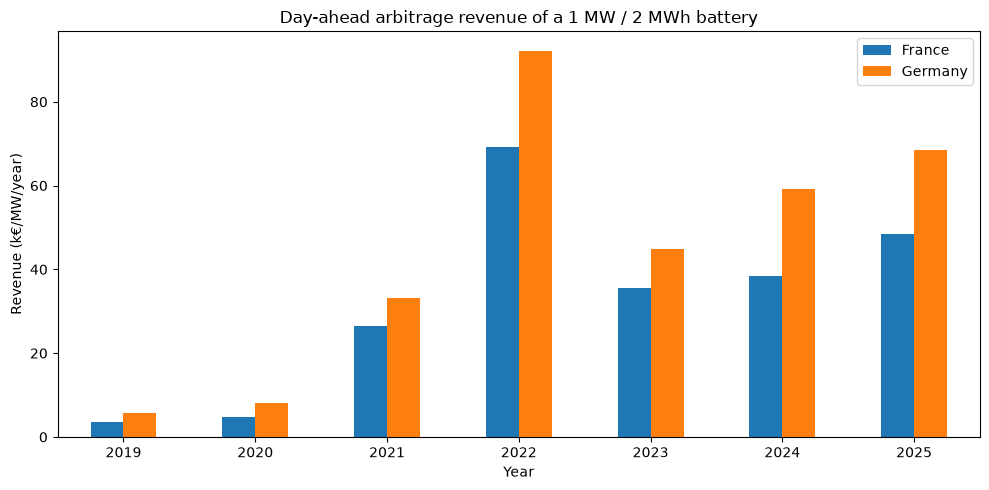

In [67]:
pack_price = {2019: 156, 2020: 137, 2021: 132, 2022: 151, 2023: 139, 2024: 115, 2025: 108} #from BNEF, expressed in $/kWh
k_by_year = {y: 10 * p / pack_price[2025] for y, p in pack_price.items()}

rev_fr = daily_revenues(fr_all, k_by_year)
rev_de = daily_revenues(de_all, k_by_year)

def annual(rev):
    return rev.groupby(pd.to_datetime(rev.index).year).sum() / 1000 # expressed in k€/MW/year

annual_rev = pd.DataFrame({"France": annual(rev_fr), "Germany": annual(rev_de)}).round(1)
annual_rev["DE/FR ratio"] = (annual_rev["Germany"] / annual_rev["France"]).round(2)
print("Annual day-ahead arbitrage revenue (k€/MW/year)")
print(annual_rev)

ax = annual_rev[["France", "Germany"]].plot(kind="bar", figsize=(10, 5), rot=0)
ax.set_xlabel("Year")
ax.set_ylabel("Revenue (k€/MW/year)")
ax.set_title("Day-ahead arbitrage revenue of a 1 MW / 2 MWh battery")
plt.tight_layout()
plt.show()

We can see that between 2019 and 2025, day-ahead arbitrage revenues rose more than ten times in both countries. A battery consistently earns more in Germany than in France, by 26% to 74% depending on the year, but the gap has not widened very strongly: the divergence observed in May is mostly a spring effect, driven by the high share of solar energy in the German energy mix. To confirm that this gap between our 2 batteries comes mostly from the sunny months. We will calculate ratios for each month of each year. Logically, we should observe larger ratios during sunny months.

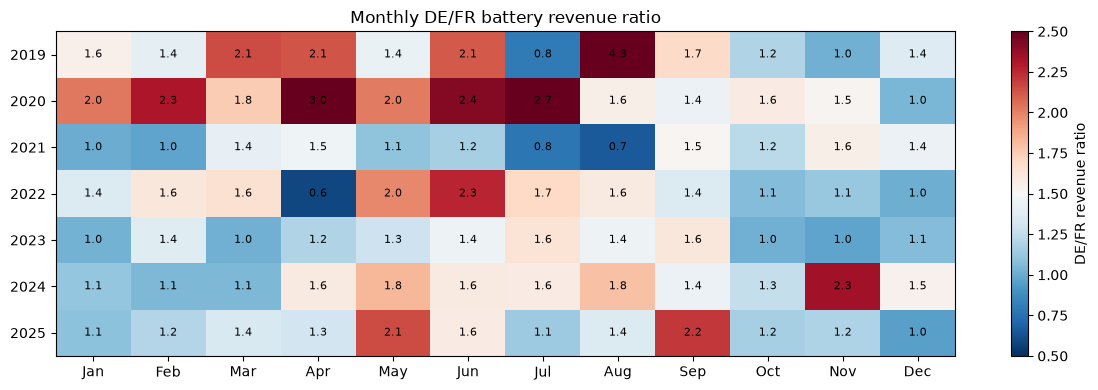

In [68]:
monthly = pd.DataFrame({
    "France": rev_fr.groupby([pd.to_datetime(rev_fr.index).year, pd.to_datetime(rev_fr.index).month]).sum(),
    "Germany": rev_de.groupby([pd.to_datetime(rev_de.index).year, pd.to_datetime(rev_de.index).month]).sum(),
})
monthly.index.names = ["year", "month"]
ratio = (monthly["Germany"] / monthly["France"]).unstack("month").round(2)

fig, ax = plt.subplots(figsize=(12, 4))
im = ax.imshow(ratio.values, cmap="RdBu_r", vmin=0.5, vmax=2.5, aspect="auto")
ax.set_xticks(range(12)); ax.set_xticklabels(["Jan","Feb","Mar","Apr","May","Jun","Jul","Aug","Sep","Oct","Nov","Dec"])
ax.set_yticks(range(len(ratio.index))); ax.set_yticklabels(ratio.index)
for i in range(ratio.shape[0]):
    for j in range(ratio.shape[1]):
        ax.text(j, i, f"{ratio.values[i, j]:.1f}", ha="center", va="center", fontsize=8)
plt.colorbar(im, label="DE/FR revenue ratio")
ax.set_title("Monthly DE/FR battery revenue ratio")
plt.tight_layout()
plt.show()

Since 2024, the German advantage is concentrated between April and September, when solar output is high (ratios of 1.4 to 2.2), while winter months show similar revenues in both countries (ratios of 1.0 to 1.2). In earlier years, the monthly ratios are noisier: revenues were small in 2019–2020, and the 2021–2023 energy crisis, including the French nuclear problems of 2022, distorted the comparison.
Following Cole and al. 2025, our degradation factor k has a major role in the determination of the profit and a small change in k can totally modify the output of our tests. To test the robusty of our study, we will realise a sensibility analysis to compare the results we have with different values of k.

In [69]:
sens = {}
for k_const in [5, 20]:
    sens[f"FR, k={k_const}"] = annual(daily_revenues(fr_all, k_const))
    sens[f"DE, k={k_const}"] = annual(daily_revenues(de_all, k_const))
sens["FR, k by year"] = annual_rev["France"]
sens["DE, k by year"] = annual_rev["Germany"]

sensitivity = pd.DataFrame(sens).round(1)

# DE/FR ratio for each assumption on k
for label in ["k=5", "k=20", "k by year"]:
    sensitivity[f"ratio, {label}"] = (sensitivity[f"DE, {label}"] / sensitivity[f"FR, {label}"]).round(2)

print("Sensitivity of annual revenue to the degradation cost (k€/MW/year)")
print(sensitivity)

Sensitivity of annual revenue to the degradation cost (k€/MW/year)
      FR, k=5  DE, k=5  FR, k=20  DE, k=20  FR, k by year  DE, k by year  \
2019      8.5     11.4       2.0       3.9            3.5            5.7   
2020      9.0     13.6       2.7       5.2            4.7            8.2   
2021     33.0     39.8      21.0      27.5           26.4           33.2   
2022     78.2    102.0      63.6      86.1           69.2           92.2   
2023     44.0     53.2      29.0      38.3           35.5           44.9   
2024     44.9     65.5      29.7      50.3           38.4           59.2   
2025     54.5     74.0      38.4      59.2           48.4           68.6   

      ratio, k=5  ratio, k=20  ratio, k by year  
2019        1.34         1.95              1.63  
2020        1.51         1.93              1.74  
2021        1.21         1.31              1.26  
2022        1.30         1.35              1.33  
2023        1.21         1.32              1.26  
2024        1.46        

As we could predict it, revenues are highly impacted by the choice of k. But we can also tell that our results are robust to the choice of degradation cost. In either way, the German battery is more profitable than the French one. Now that we noticed this result, we can ask ourselves the reasons of this high differences between the two countries.

### 3. What drives the gap between France and Germany ?

We will try to analyse the energy production mix of both countries to understand better from wher our result comes from. For that, we download public generation data for both countries over our 2019-2025 period.

### 3.1. Generation data, 2019-2025

In [70]:
def get_power(country, start, end, max_retries=5):
    """Net electricity production by source from Energy-Charts (MW), with cache and retry."""
    cache_file = CACHE / f"power_{country}_{start}_{end}.csv"
    if cache_file.exists():
        df = pd.read_csv(cache_file, index_col=0, parse_dates=True)
        df.index = pd.to_datetime(df.index, utc=True).tz_convert("Europe/Paris")
        return df

    url = "https://api.energy-charts.info/public_power"
    wait = 10
    for attempt in range(max_retries):
        r = requests.get(url, params={"country": country, "start": start, "end": end}, timeout=60)
        if r.status_code == 429:
            print(f"429 on {country} {start} - waiting {wait}s (attempt {attempt+1}/{max_retries})")
            time.sleep(wait)
            wait *= 2
            continue
        r.raise_for_status()
        data = r.json()
        idx = pd.to_datetime(data["unix_seconds"], unit="s", utc=True).tz_convert("Europe/Paris")
        df = pd.DataFrame({pt["name"]: pt["data"] for pt in data["production_types"]}, index=idx)
        df.to_csv(cache_file)
        time.sleep(3)
        return df

    raise RuntimeError(f"Still rate-limited after {max_retries} attempts for {country} {start}")

# look at one day for each country
for c in ["fr", "de"]:
    test = get_power(c, "2025-05-11", "2025-05-11")
    print(c.upper(), "-", len(test), "time steps")
    print(list(test.columns), "\n")

FR - 24 time steps
['Hydro pumped storage consumption', 'Battery Consumption', 'Cross border electricity trading', 'Nuclear', 'Hydro Run-of-River', 'Biomass', 'Fossil oil', 'Fossil gas', 'Hydro water reservoir', 'Hydro pumped storage', 'Battery', 'Waste', 'Wind offshore', 'Wind onshore', 'Solar', 'Load', 'Residual load', 'Renewable share of load', 'Renewable share of generation'] 

DE - 96 time steps
['Hydro pumped storage consumption', 'Cross border electricity trading', 'Hydro Run-of-River', 'Biomass', 'Fossil brown coal / lignite', 'Fossil hard coal', 'Fossil oil', 'Fossil coal-derived gas', 'Fossil gas', 'Geothermal', 'Hydro water reservoir', 'Hydro pumped storage', 'Others', 'Waste', 'Wind offshore', 'Wind onshore', 'Solar', 'Load', 'Residual load', 'Renewable share of load', 'Renewable share of generation'] 



In [71]:
GEN_COLS = ["Solar", "Nuclear", "Wind onshore", "Wind offshore", "Fossil gas"]

def daily_features(power):
    """Daily energy (MWh) and shares of load."""
    power = power.copy()
    gen = [c for c in GEN_COLS if c in power.columns]
    power[gen] = power[gen].fillna(0)                      # no data = no production (night, offshore before 2023, DE nuclear after April 2023)
    daily = power.groupby(power.index.date).sum(min_count=20)
    out = pd.DataFrame(index=daily.index)
    out["solar_share"] = daily["Solar"] / daily["Load"]
    out["wind_share"] = (daily["Wind onshore"] + daily.get("Wind offshore", 0)) / daily["Load"]
    if "Nuclear" in daily.columns:
        out["nuclear_share"] = daily["Nuclear"] / daily["Load"]
    out["load_GWh"] = daily["Load"] / 1000
    return out

feat_fr = daily_features(power_fr)
feat_de = daily_features(power_de)

print(f"Missing days – France: {feat_fr.isna().any(axis=1).sum()} | Germany: {feat_de.isna().any(axis=1).sum()}\n")

# average shares by year
year_fr = pd.to_datetime(feat_fr.index).year
year_de = pd.to_datetime(feat_de.index).year
summary = pd.DataFrame({
    "Solar FR": feat_fr["solar_share"].groupby(year_fr).mean(),
    "Solar DE": feat_de["solar_share"].groupby(year_de).mean(),
    "Wind FR": feat_fr["wind_share"].groupby(year_fr).mean(),
    "Wind DE": feat_de["wind_share"].groupby(year_de).mean(),
    "Nuclear FR": feat_fr["nuclear_share"].groupby(year_fr).mean(),
    "Nuclear DE": feat_de["nuclear_share"].groupby(year_de).mean(),
}).mul(100).round(1)

print("Average daily share of load (%)")
print(summary)

Missing days – France: 2 | Germany: 0

Average daily share of load (%)
      Solar FR  Solar DE  Wind FR  Wind DE  Nuclear FR  Nuclear DE
2019       2.7       8.7      7.1     24.8        82.1        14.4
2020       3.1       9.9      8.5     26.3        75.4        12.7
2021       3.2       9.4      7.6     22.4        79.1        13.1
2022       4.4      11.7      8.4     25.0        62.4         6.9
2023       5.5      12.4     11.4     30.2        76.1         1.4
2024       5.9      13.5     10.6     28.9        84.7         0.0
2025       7.5      15.9     11.2     28.0        86.2         0.0


To visualise more easily the data, we put it in a graph :

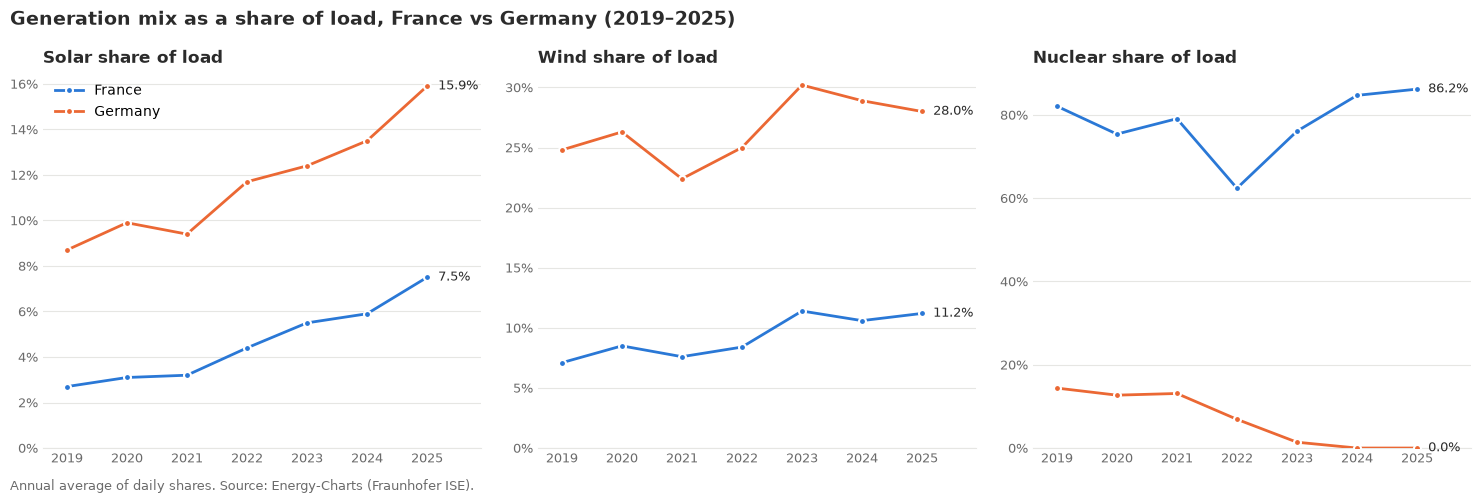

In [ ]:
COLORS = {"FR": "#2a78d6", "DE": "#eb6834"}
NAMES = {"FR": "France", "DE": "Germany"}
INK, MUTED, GRID = "#2b2b2b", "#6b6b6b", "#e6e6e3"

fig, axes = plt.subplots(1, 3, figsize=(15, 4.8))
for ax, source in zip(axes, ["Solar", "Wind", "Nuclear"]):
    for c in ["FR", "DE"]:
        y = summary[f"{source} {c}"]
        ax.plot(summary.index, y, color=COLORS[c], lw=2, marker="o", ms=5,
                markeredgecolor="white", markeredgewidth=1.5, label=NAMES[c], zorder=3)
        # value of the last year, written next to the line
        ax.annotate(f"{y.iloc[-1]:.1f}%", xy=(summary.index[-1], y.iloc[-1]),
                    xytext=(8, 0), textcoords="offset points", va="center",
                    fontsize=9, color=INK)
    ax.set_title(f"{source} share of load", loc="left", fontsize=12, color=INK, fontweight="bold")
    ax.set_xticks(summary.index)
    ax.set_xlim(summary.index[0] - 0.4, summary.index[-1] + 0.9)
    ax.set_ylim(bottom=0)
    ax.yaxis.set_major_formatter(lambda v, _: f"{v:.0f}%")
    ax.grid(axis="y", color=GRID, lw=0.8)
    ax.set_axisbelow(True)
    for s in ["top", "right", "left"]:
        ax.spines[s].set_visible(False)
    ax.spines["bottom"].set_color(GRID)
    ax.tick_params(colors=MUTED, labelsize=9, length=0)

axes[0].legend(frameon=False, fontsize=10, loc="upper left")
fig.suptitle("Generation mix as a share of load, France vs Germany (2019–2025)",
             x=0.01, ha="left", fontsize=14, color=INK, fontweight="bold")
fig.text(0.01, -0.02, "Annual average of daily shares. Source: Energy-Charts (Fraunhofer ISE).",
         fontsize=9, color=MUTED)
plt.tight_layout()
plt.show()

### 3.2. Solar share and battery revenues

In the chart above shows how much of each country's electricity consumption is covered by solar, wind and nuclear power, on average, for each year between 2019 and 2025.

Solar : Germany produces much more solar electricity than France: in 2025, solar covers about 16% of German consumption, against 7.5% in France. Solar is growing in both countries, and it is growing faster in France in relative terms (almost three times more than in 2019), but France is still far behind Germany.

Wind : The same pattern appears for wind: about 28% of German consumption in 2025, against 11% in France.

Nuclear : This is where the two countries are completely different. In France, nuclear power produces the equivalent of 75% to 86% of the country's consumption every year, except in 2022, when many reactors were stopped for maintenance and corrosion problems. In Germany, nuclear power slowly disappeared and reached zero after the last reactors were closed in April 2023.

These numbers are consistent with the price shapes we observed. Germany has more solar, so its midday prices fall lower. But the most important difference is in the evening: when the sun sets, Germany has no nuclear power left and relies more on gas plants, which are expensive and set a high price. France still has a large amount of cheap nuclear power, which keeps its evening prices low. A battery earns money from the gap between midday and evening prices, so this gap is larger in Germany.

### 3.3. Regression analysis

Gas price: 2557 days, from 5 to 239 USD/MWh
Dataset – France: 2555 days | Germany: 2557 days


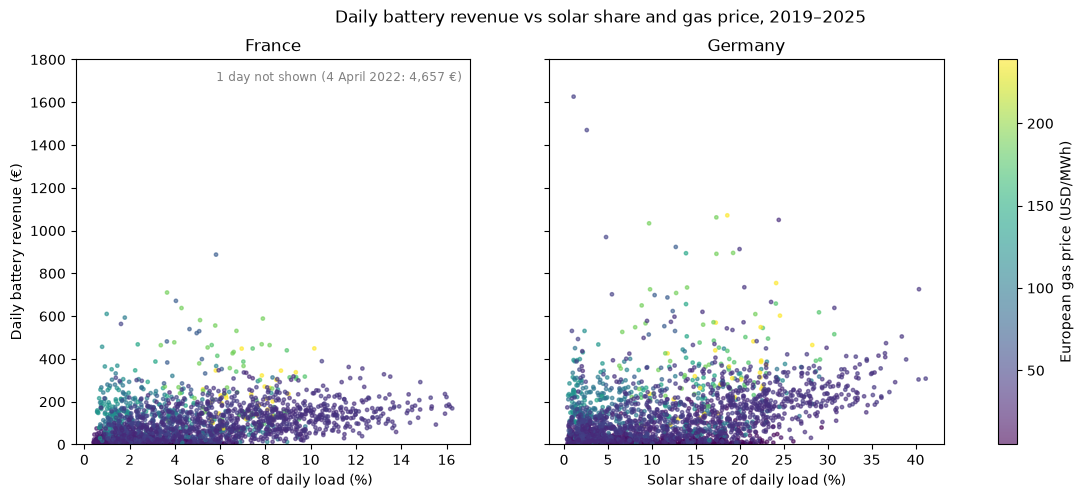

In [ ]:
# European natural gas price (IMF, based on the Dutch TTF hub), monthly, USD/MMBtu – via FRED
gas_m = pd.read_csv("https://fred.stlouisfed.org/graph/fredgraph.csv?id=PNGASEUUSDM")
gas_m.columns = ["date", "gas"]
gas_m["date"] = pd.to_datetime(gas_m["date"])
gas_m = gas_m.set_index("date")["gas"] * 3.412 # USD/MMBtu -> USD/MWh (1 MWh = 3.412 MMBtu)

# give each day the price of its month
days = pd.date_range("2019-01-01", "2025-12-31")
ttf = pd.Series(gas_m.reindex(days.to_period("M").to_timestamp()).values, index=days.date)
print(f"Gas price: {ttf.notna().sum()} days, from {ttf.min():.0f} to {ttf.max():.0f} USD/MWh")

def build_dataset(rev, feat, gas):
    df = feat.join(rev.rename("revenue")).join(gas.rename("gas"))
    df.index = pd.to_datetime(df.index)
    return df.dropna(subset=["revenue", "solar_share", "gas"])

data_fr = build_dataset(rev_fr, feat_fr, ttf)
data_de = build_dataset(rev_de, feat_de, ttf)
print(f"Dataset – France: {len(data_fr)} days | Germany: {len(data_de)} days")

Y_MAX = 1800

fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)
for ax, (name, df) in zip(axes, [("France", data_fr), ("Germany", data_de)]):
    sc = ax.scatter(df["solar_share"] * 100, df["revenue"], c=df["gas"], cmap="viridis", s=6, alpha=0.6)
    ax.set_title(name)
    ax.set_xlabel("Solar share of daily load (%)")
    ax.set_ylim(0, Y_MAX)

    n_out = (df["revenue"] > Y_MAX).sum()
    if n_out:
        ax.text(0.98, 0.97, f"{n_out} day not shown (4 April 2022: {df['revenue'].max():,.0f} €)",
                transform=ax.transAxes, ha="right", va="top", fontsize=8.5, color="grey")

axes[0].set_ylabel("Daily battery revenue (€)")
plt.colorbar(sc, ax=axes, label="European gas price (USD/MWh)")
plt.suptitle("Daily battery revenue vs solar share and gas price, 2019–2025")
plt.show()

We can observe that, in general, at a given solar share of daily load, our daily battery revenue follows European gas prices: when gas prices are high, our daily battery revenue tends to be higher as well. We can also observe that a larger solar share of daily load is associated with a higher daily battery revenue. These two charts confirm what we were saying earlier: a large solar share and high gas prices are both associated with higher daily battery revenues. We need to note that the two countries do not cover the same range: the solar share reaches up to 40% of daily load on some days in Germany, against 16% at most in France. One day is not shown in the French chart (4 April 2022, 4,657 €), as it was flattening the rest of the graph.

In [74]:
for name, df in [("France", data_fr), ("Germany", data_de)]:
    print(f"{name} – top 3 days:")
    print(df["revenue"].nlargest(3).round(0), "\n")

France – top 3 days:
2022-04-04    4657.0
2022-10-04     888.0
2022-09-27     711.0
Name: revenue, dtype: float64 

Germany – top 3 days:
2024-12-12    1626.0
2024-11-06    1470.0
2022-08-28    1071.0
Name: revenue, dtype: float64 



In [ ]:
import statsmodels.api as sm

def run_regression(df, name):
    X = df[["solar_share", "wind_share", "nuclear_share", "gas"]].copy()
    X[["solar_share", "wind_share", "nuclear_share"]] *= 100 # shares in % so coefficients read "€ per percentage point"
    X = sm.add_constant(X)
    model = sm.OLS(df["revenue"], X).fit(cov_type="HAC", cov_kwds={"maxlags": 7})
    print(f"===== {name} =====")
    print(model.summary().tables[1])
    print(f"R²: {model.rsquared:.2f}\n")
    return model

model_fr = run_regression(data_fr, "France")
model_de = run_regression(data_de, "Germany")

# side-by-side comparison
coefs = pd.DataFrame({"France": model_fr.params, "Germany": model_de.params}).round(2)
pvals = pd.DataFrame({"France": model_fr.pvalues, "Germany": model_de.pvalues}).round(3)
print("Coefficients (€ per day)")
print(coefs, "\n")
print("p-values")
print(pvals)

===== France =====
                    coef    std err          z      P>|z|      [0.025      0.975]
---------------------------------------------------------------------------------
const            -4.6778     42.804     -0.109      0.913     -88.572      79.217
solar_share       9.6244      0.896     10.739      0.000       7.868      11.381
wind_share        2.1554      0.340      6.337      0.000       1.489       2.822
nuclear_share    -0.3575      0.539     -0.664      0.507      -1.413       0.698
gas               1.1991      0.111     10.762      0.000       0.981       1.417
R²: 0.23

===== Germany =====
                    coef    std err          z      P>|z|      [0.025      0.975]
---------------------------------------------------------------------------------
const            27.5050     18.100      1.520      0.129      -7.969      62.979
solar_share       4.4695      0.519      8.607      0.000       3.452       5.487
wind_share        0.0969      0.247      0.393   

To go further than the charts, we run a linear regression for each country. We try to explain the daily battery revenue with the solar share, the wind share and the nuclear share of daily load (in percentage points), and with the European gas price (in USD/MWh). Standard errors are corrected for autocorrelation (Newey-West), as each day tends to look like the day before.

| Variable | France | Germany |
|---|---|---|
| Solar share (€ per point) | 9.6 | 4.5 |
| Wind share (€ per point) | 2.2 | 0.1 |
| Nuclear share (€ per point) | −0.4 | −5.6 |
| Gas price (€ per USD/MWh) | 1.20 | 1.66 |
| R² | 0.23 | 0.45 |


Solar : In both countries, more solar means more revenue for the battery. Surprisingly, one more point of solar adds more revenue in France (9.6 € per day) than in Germany (4.5 € per day). We can explain this by thinking about the fact that Germany already has a lot of solar: midday prices are often already very low or negative, so each additional point of solar deepens the midday trough less. Solar cannibalises its own value. In 2025, solar adds about the same amount per day in both countries (around 70 €), so solar alone does not explain the gap between France and Germany.

Gas : A higher gas price means more revenue in both countries, but the effect is stronger in Germany (1.66 € against 1.20 € per day for each USD/MWh). This is consistent with gas plants setting the evening price more often in Germany thanks to the French nuclear energy. With a gas price of about 40 USD/MWh, this represents around 18 € per day more in Germany, or roughly 6 to 7 k€ per year.

Nuclear : In France, the nuclear share has no significant effect: it is always high and changes little from one day to the next. In Germany, a higher nuclear share is associated with lower revenues. i think that this is because German nuclear power decreased a lot until 2023 while solar and battery revenues were rising, so this coefficient also captures this descending trend over time.

Overall : The regression suggests that the German advantage comes less from solar power than from the evening: German revenues depend more on the gas price, as Germany no longer has nuclear power to keep evening prices low. This matches the most profitable German days, which are winter days with no wind and no sun, not sunny days.

Limits : We need to be careful with these results: they show that some variables move together, not that one causes the other. Our model also only explains part of the daily revenues: about 23% in France and 45% in Germany. We only have a monthly gas price, so we cannot see how gas prices change from one day to the next. Finally, we use a linear model, which assumes that each extra point of solar always has the same effect, while we saw that this effect gets smaller when there is already a lot of solar.

### 4. Limitations

Our model is a simplified version of how a real battery works, and our results must be read with this in mind.

The battery model : 
- Perfect foresight : We assume that the battery knows all the prices of the day in advance. In reality, a battery operator has to submit its bids before the day-ahead auction, without knowing the final prices. Our revenues are therefore an upper bound of what a battery could earn on the day-ahead market.
- Day-ahead market only : A real battery also trades on the intraday market and sells ancillary services to the grid operator (frequency reserves), which are often a large part of its revenues. For comparison, I found a source saying that the enervis Battery Storage Index forecast about 134 k€/MW for a 1 MW / 2 MWh battery in Germany in 2025, all markets included, while our day-ahead model gives 68.7 k€/MW. Our revenues therefore only show part of what a real battery earns.
- Price taker : We assume that our battery is too small to change market prices. This is true for a 1 MW battery, but not for the several gigawatts of batteries now being built in Germany: as more batteries charge at midday and discharge in the evening, they reduce the very price gap they earn money from.

The data :
- Since October 2025, day-ahead prices are published every 15 minutes. We average them to hourly values so that all years are comparable, which slightly reduces the price gaps the battery can capture at the end of 2025.
- We only have a monthly gas price, so we cannot see how gas prices change from one day to the next.

The degradation cost : The cost of battery wear $k$ is uncertain: it depends on battery prices and on how many cycles a battery can really do before it wears out. This is why we tested several values of $k$. Our main conclusion (a battery earns more in Germany than in France) holds for all of them, but the size of the revenues and of their increase since 2019 depends on this choice.

The regression : Our regression shows correlations, not causes. It only explains part of the daily revenues, and it assumes that each extra point of solar always has the same effect, while this effect gets smaller when there is already a lot of solar. Some variables also move together over time (more solar, less German nuclear power), which makes their effects harder to separate.

### 5. Conclusion

At the beginning of this project, we wanted to understand why a battery earns less in France than in Germany, and how this gap has evolved since 2019.

Our first look at a single sunny day suggested a clear answer: German prices explode in the evening while French prices stay low, and we clearly wanted to install our battery in Germany. The full simulation over seven years confirms this first intuition, but makes it more precise.

Between 2019 and 2025, day-ahead arbitrage revenues rose more than ten times in both countries: flexibility has become much more valuable on both sides of the border. A battery consistently earns more in Germany than in France, by 26% to 74% depending on the year, and this result holds for every value of the degradation cost we tested. However, the gap has not widened very strongly over time. The strong divergence we observed in May is mostly a spring effect: since 2024, the German advantage is concentrated between April and September, while winter months show similar revenues in both countries.

The reason behind this gap is not only solar power. Germany has two to three times more solar than France, which makes its midday prices fall lower, but each extra point of solar adds less and less value as solar becomes abundant. The main difference comes from the evening: when the sun sets, Germany relies on gas plants, which set a high price, while France still has a large amount of cheap nuclear power that keeps its prices low. This is why German battery revenues depend more on the gas price, and why the most profitable German days are winter days with no wind and no sun.

These results only cover the day-ahead market, with a simplified battery that knows prices in advance, so they show part of what a real battery can earn. Still, they show a clear trend: as solar keeps growing in both countries and as Germany relies more on gas in the evening, the value of storage keeps rising, and the French market could become more attractive for batteries as its own solar share continues to grow.